Import Libraries

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

Load Datasets

In [26]:
students = pd.read_csv("../Cleaned_Data/Students_Cleaned.csv")
courses = pd.read_csv("../Cleaned_Data/Course_Catalogue_Cleaned.csv")
interactions = pd.read_csv(
    "../Cleaned_Data/Student_Course_Interactions_Cleaned.csv"
)

Understand the datasets

In [27]:
print("Student Columns:")
print(students.columns.tolist())

print("\nInteraction Columns:")
print(interactions.columns.tolist())

print("\nCourse Columns:")
print(courses.columns.tolist())

interactions.columns = interactions.columns.str.strip()
students.columns = students.columns.str.strip()
courses.columns = courses.columns.str.strip()

Student Columns:
['Student_ID', 'Batch_Year', 'Semester', 'Branch', 'School', 'Campus', 'Age', 'Gender', 'Class12_Stream', 'CGPA', 'Previous_Semester_SGPA', 'Attendance_Percentage', 'Weekly_Study_Hours', 'Num_Prior_Exploratory_Courses', 'Num_Certifications', 'Internship_Experience', 'Interests', 'Secondary_Interests', 'Hobbies', 'Technical_Skills', 'Skill_Level', 'Career_Goal', 'Learning_Preference', 'Preferred_Difficulty', 'Workload_Preference', 'Preferred_Slot', 'Confusion_Level', 'Confusion_Reason', 'Selection_Confidence', 'Previous_Course_Satisfaction', 'Survey_Timestamp', 'Selected_Course_Code', 'Selected_Exploratory_Course']

Interaction Columns:
['Interaction_ID', 'Student_ID', 'Course_ID', 'Course_Code', 'Interaction_Type', 'Interaction_Date', 'Time_Spent_Minutes', 'Recommended_By', 'Rating_Given', 'Suitability_Label']

Course Columns:
['Course_ID', 'AY', 'School', 'Sem', 'Course Code', 'Course', 'CREDIT', 'Minor Stream', 'Slot', 'Schedule', 'Remarks', 'Primary_Domain', 'Second

Merge datasets

In [28]:
# Rename course column
courses = courses.rename(
    columns={"Course Code": "Course_Code"}
)

# Merge student information
df = pd.merge(
    interactions[["Student_ID", "Course_Code", "Suitability_Label"]],
    students,
    on="Student_ID",
    how="inner"
)

# Merge course information
df = pd.merge(
    df,
    courses,
    on="Course_Code",
    how="left"
)

print("Final Dataset Shape:", df.shape)
df.head()

Final Dataset Shape: (6620, 54)


,Student_ID,Course_Code,Suitability_Label,Batch_Year,Semester,Branch,School_x,Campus,Age,Gender,...,Remarks,Primary_Domain,Secondary_Domain,Difficulty_Level,Workload_Level,Teaching_Style,Technical_Prerequisite,Popularity_Index,Skill_Tags,Typical_Career_Paths
0,STU0001,INTB2024,medium,2023,5,B.Tech CSE - AI & ML,SOCS,Kandoli,20.0,male,...,Not applicable to BBA Foreign Trade Students,Supply Chain & Trade,Data Analytics,3.0,Medium,Practical,Not Specified,3.0,Python,Supply Chain/Operations Manager; Data Scientist
1,STU0001,CLCC3008,medium,2023,5,B.Tech CSE - AI & ML,SOCS,Kandoli,20.0,male,...,Not Specified,Law,Human Resources,4.0,High,Theory,Not Specified,3.0,Public Speaking; Research Writing; Legal Research,Cybersecurity Analyst; Lawyer/Legal Advisor; H...
2,STU0001,SMJM2010,med,2023,5,B.Tech CSE - AI & ML,SOCS,Kandoli,20.0,male,...,Not Specified,Media & Journalism,Politics & Governance,2.0,Medium,Discussion,Not Specified,3.0,Adobe Photoshop; Video Editing; Content Writin...,Marketing Manager; Journalist/Media Profession...
3,STU0001,SUEN3019,medium,2023,5,B.Tech CSE - AI & ML,SOCS,Kandoli,20.0,male,...,Not Specified,Energy & Sustainability,Civil & Construction,2.0,Medium,Theory,Not Specified,3.0,Process Simulation; AutoCAD,Chemical/Petroleum Engineer; Energy/Sustainabi...
4,STU0001,LSPS3002,medium,2023,5,B.Tech CSE - AI & ML,SOCS,Kandoli,20.0,male,...,Not Specified,Politics & Governance,Cyber Security,3.0,Medium,Discussion,Not Specified,4.0,Public Speaking; Legal Research; Linux,Energy/Sustainability Consultant; Lawyer/Legal...


Data preparation

In [29]:
# Remove missing target values
df = df.dropna(subset=["Suitability_Label"])

# Remove duplicate records
df = df.drop_duplicates()

# Remove identifiers and leakage-prone columns
columns_to_drop = [
    "Student_ID",
    "Course_Code",
    "Selected_Course_Code",
    "Selected_Exploratory_Course",
    "Selection_Confidence"
]

df = df.drop(
    columns=[col for col in columns_to_drop if col in df.columns],
    errors="ignore"
)

# Separate features and target
X = df.drop("Suitability_Label", axis=1)
y = df["Suitability_Label"]

print("Features Shape:", X.shape)
print("Target Distribution:")
print(y.value_counts())

Features Shape: (5153, 48)
Target Distribution:
Suitability_Label
medium      1698
high        1646
low         1292
hi           149
moderate     130
med          122
lo            81
-             23
unknown       12
Name: count, dtype: int64


Identify numerical and categorical columns

In [30]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['Age', 'CGPA', 'Previous_Semester_SGPA', 'Attendance_Percentage', 'Weekly_Study_Hours', 'Num_Prior_Exploratory_Courses', 'Num_Certifications', 'Confusion_Level', 'Previous_Course_Satisfaction', 'AY', 'CREDIT', 'Difficulty_Level', 'Popularity_Index']

Categorical Features: ['Batch_Year', 'Semester', 'Branch', 'School_x', 'Campus', 'Gender', 'Class12_Stream', 'Internship_Experience', 'Interests', 'Secondary_Interests', 'Hobbies', 'Technical_Skills', 'Skill_Level', 'Career_Goal', 'Learning_Preference', 'Preferred_Difficulty', 'Workload_Preference', 'Preferred_Slot', 'Confusion_Reason', 'Survey_Timestamp', 'Course_ID', 'School_y', 'Sem', 'Course', 'Minor Stream', 'Slot', 'Schedule', 'Remarks', 'Primary_Domain', 'Secondary_Domain', 'Workload_Level', 'Teaching_Style', 'Technical_Prerequisite', 'Skill_Tags', 'Typical_Career_Paths']


Preprocessing

In [31]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Train-test split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 4122
Testing Samples: 1031


Random Forest Model

In [33]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Model prediction

In [34]:
y_pred = rf_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,low,high
1,high,medium
2,low,medium
3,lo,low
4,high,high
5,low,low
6,high,high
7,high,high
8,high,medium
9,high,high


Model evaluation

In [35]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 50.34 %

Classification Report:
              precision    recall  f1-score   support

           -       0.00      0.00      0.00         5
          hi       0.14      0.07      0.09        30
        high       0.48      0.58      0.53       329
          lo       0.33      0.12      0.18        16
         low       0.67      0.56      0.61       259
         med       0.13      0.08      0.10        24
      medium       0.47      0.51      0.49       340
    moderate       0.14      0.08      0.10        26
     unknown       0.00      0.00      0.00         2

    accuracy                           0.50      1031
   macro avg       0.26      0.22      0.23      1031
weighted avg       0.50      0.50      0.49      1031



Confusion matrix

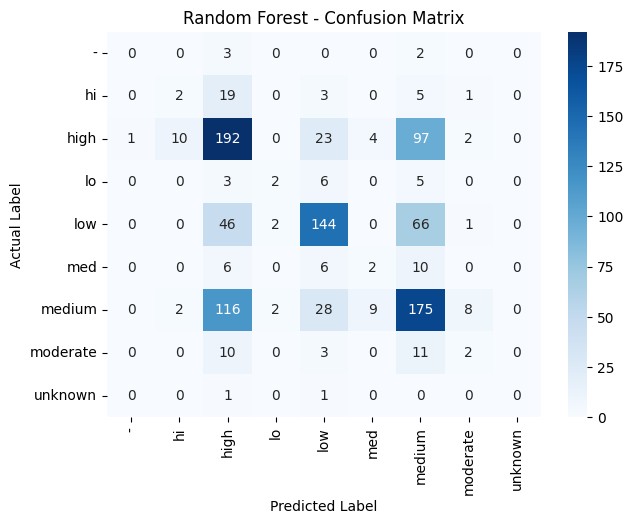

In [36]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest - Confusion Matrix")
plt.show()

Feature importance

In [37]:
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf_model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
2,num__Previous_Semester_SGPA,0.013982
1,num__CGPA,0.013470
4,num__Weekly_Study_Hours,0.011835
3,num__Attendance_Percentage,0.011436
7,num__Confusion_Level,0.009611
6,num__Num_Certifications,0.007797
0,num__Age,0.007390
12,num__Popularity_Index,0.007344
8,num__Previous_Course_Satisfaction,0.007334
5,num__Num_Prior_Exploratory_Courses,0.006578


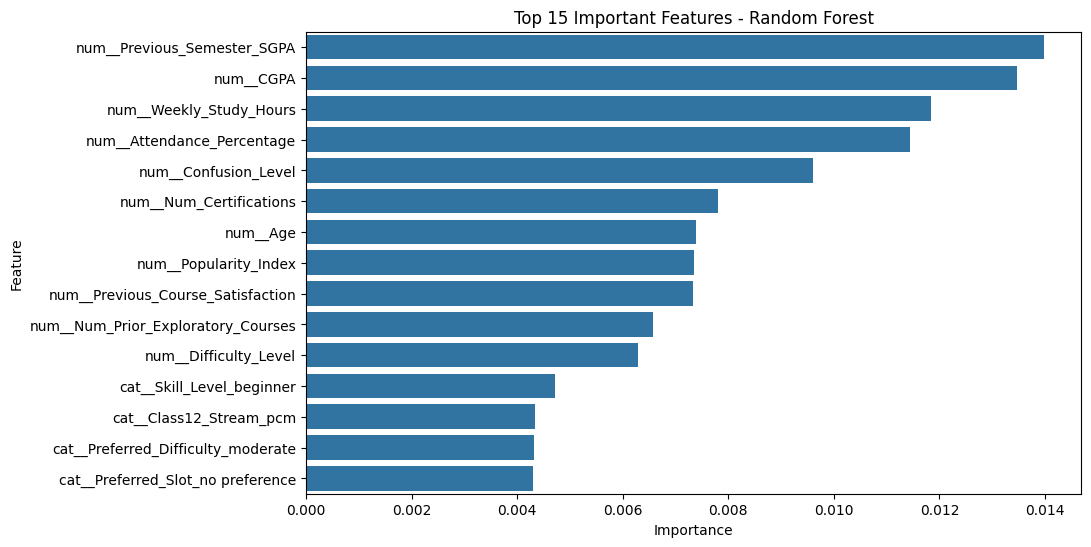

In [38]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.show()

Conclusion

In [39]:
## Conclusion

#The Random Forest Classifier was implemented to predict course
#suitability based on student and course-related characteristics.

#The model was evaluated using accuracy, precision, recall,
#F1-score and a confusion matrix.

#Feature importance was also analyzed to identify the factors
#contributing most to course suitability predictions.